# 05 – Huấn luyện mô hình dự báo rời bỏ và đánh giá

**Đầu vào:** bảng `churn_dataset` (notebook 04). **Đầu ra:** bảng so sánh mô hình, biểu đồ độ suy giảm theo thời gian và file `ket_qua_mo_hinh.csv`.

**Ý tưởng:**
1. **Chia theo thời gian**: huấn luyện trên các ngày cutoff cũ, kiểm tra trên các ngày cutoff mới hơn.
2. So sánh với **mô hình cơ sở (baseline)** đơn giản để biết mô hình phức tạp có thật sự đáng dùng không.
3. Kiểm tra mô hình **suy giảm** thế nào khi càng xa thời điểm huấn luyện.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from getpass import getpass
from pathlib import Path
from sqlalchemy import create_engine
from sqlalchemy.engine import URL
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

pd.options.display.float_format = "{:,.3f}".format
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
Path("figures").mkdir(exist_ok=True)

SEED = 42
TOP_K = 500

engine = create_engine(URL.create(
    "postgresql+psycopg2", username="postgres", password=getpass("Mật khẩu PostgreSQL: "),
    host="localhost", port=5432, database="Churn_Data"))

Mật khẩu PostgreSQL:  ········


## 1. Đọc dữ liệu và chia train/test theo thời gian

In [2]:
du_lieu = pd.read_sql("SELECT * FROM churn_dataset WHERE churn_90 IS NOT NULL", engine)
du_lieu["cutoff_date"] = pd.to_datetime(du_lieu["cutoff_date"])

dac_trung = ["recency", "tenure", "frequency", "monetary", "aov", "sku_per_invoice", "qty_per_line",
             "freq_90d", "mon_90d", "freq_180d", "mon_180d", "freq_365d", "mon_365d", "xu_huong_freq",
             "avg_gap", "mua_mot_lan", "rec_gap_ratio", "so_don_hoan", "ti_le_hoan", "is_uk"]

cac_ngay = sorted(du_lieu["cutoff_date"].unique())
ngay_train, ngay_test = cac_ngay[:3], cac_ngay[3:]          # 3 mốc đầu để học, các mốc sau để kiểm tra
print("Huấn luyện trên:", [str(d)[:10] for d in ngay_train])
print("Kiểm tra trên:  ", [str(d)[:10] for d in ngay_test])

train = du_lieu[du_lieu["cutoff_date"].isin(ngay_train)]
X_train, y_train = train[dac_trung], train["churn_90"].astype(int)
print(f"Tập train: {len(train):,} dòng, tỷ lệ rời bỏ {y_train.mean() * 100:.1f}%")

Huấn luyện trên: ['2010-03-09', '2010-06-09', '2010-09-09']
Kiểm tra trên:   ['2010-12-09', '2011-03-09', '2011-06-09', '2011-09-09']
Tập train: 7,973 dòng, tỷ lệ rời bỏ 45.1%


**Vì sao không chia ngẫu nhiên?** Nhãn của mốc cutoff cuối trong tập train (09/09/2010) kết thúc vào 08/12/2010, **trước** mốc kiểm tra đầu tiên (09/12/2010).
Nhờ vậy mô hình không thể nhìn thấy kết quả của giai đoạn kiểm tra khi học. Chia ngẫu nhiên sẽ làm lẫn quá khứ và tương lai nên kết quả đẹp hơn thực tế.

## 2. Huấn luyện các mô hình
- **Baseline 1 – luật recency:** khách vắng càng lâu càng dễ rời bỏ (không cần học).
- **Baseline 2 – Logistic Regression:** mô hình tuyến tính đơn giản, dễ giải thích.
- **Random Forest:** nhiều cây quyết định, bắt được quan hệ phức tạp.
- **Gradient Boosting:** các cây học nối tiếp nhau để sửa lỗi cho nhau. 

In [3]:
# Logistic Regression cần giảm độ lệch của các cột tiền/số lần (log1p) và chuẩn hóa thang đo
cot_log = ["recency", "tenure", "frequency", "monetary", "aov", "freq_90d", "mon_90d", "freq_180d",
           "mon_180d", "freq_365d", "mon_365d", "so_don_hoan"]

def chuan_bi_logistic(X):
    X = X.copy()
    X[cot_log] = np.log1p(X[cot_log].clip(lower=0))
    return X

logistic = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, C=0.5))
logistic.fit(chuan_bi_logistic(X_train), y_train)

rung = RandomForestClassifier(n_estimators=300, min_samples_leaf=20, n_jobs=-1, random_state=SEED)
rung.fit(X_train, y_train)

boosting = HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=200, random_state=SEED)
boosting.fit(X_train, y_train)
print("Đã huấn luyện xong 3 mô hình")

Đã huấn luyện xong 3 mô hình


## 3. Đánh giá trên từng ngày cutoff của tập kiểm tra

In [4]:
def danh_gia(y, diem):
    """AUC, Precision@500 và Lift@500 của một cách chấm điểm rủi ro."""
    top = np.argsort(-diem)[:TOP_K]                 # 500 khách có điểm rủi ro cao nhất
    p_k = y[top].mean()
    return {"AUC": roc_auc_score(y, diem), "Precision@500": p_k, "Lift@500": p_k / y.mean()}

ket_qua = []
for ngay in ngay_test:
    t = du_lieu[du_lieu["cutoff_date"] == ngay]
    y = t["churn_90"].astype(int).to_numpy()

    diem = {
        "Baseline 1: luật recency": t["recency"].to_numpy(),
        "Baseline 2: Logistic Regression": logistic.predict_proba(chuan_bi_logistic(t[dac_trung]))[:, 1],
        "Random Forest": rung.predict_proba(t[dac_trung])[:, 1],
        "Gradient Boosting": boosting.predict_proba(t[dac_trung])[:, 1],
    }
    for ten_mo_hinh, d in diem.items():
        ket_qua.append({"cutoff": str(ngay)[:10], "mo_hinh": ten_mo_hinh, "ti_le_roi_bo": y.mean(), **danh_gia(y, d)})

ket_qua = pd.DataFrame(ket_qua)
ket_qua.pivot(index="cutoff", columns="mo_hinh", values="AUC")

mo_hinh,Baseline 1: luật recency,Baseline 2: Logistic Regression,Gradient Boosting,Random Forest
cutoff,,,,
2010-12-09,0.711,0.795,0.789,0.794
2011-03-09,0.714,0.776,0.751,0.764
2011-06-09,0.748,0.794,0.779,0.796
2011-09-09,0.707,0.759,0.726,0.754


In [5]:
# Precision@500 và tỷ lệ rời bỏ chung của từng ngày cutoff
bang_p = ket_qua.pivot(index="cutoff", columns="mo_hinh", values="Precision@500")
bang_p["Tỷ lệ rời bỏ chung"] = ket_qua.groupby("cutoff")["ti_le_roi_bo"].first()
bang_p

mo_hinh,Baseline 1: luật recency,Baseline 2: Logistic Regression,Gradient Boosting,Random Forest,Tỷ lệ rời bỏ chung
cutoff,,,,,
2010-12-09,0.892,0.934,0.922,0.940,0.690
2011-03-09,0.844,0.872,0.836,0.850,0.633
2011-06-09,0.880,0.906,0.896,0.904,0.643
2011-09-09,0.724,0.790,0.766,0.794,0.493


In [6]:
# Trung bình trên các ngày kiểm tra
tong_hop = ket_qua.groupby("mo_hinh")[["AUC", "Precision@500", "Lift@500"]].mean().sort_values("AUC", ascending=False)
tong_hop

,AUC,Precision@500,Lift@500
mo_hinh,,,
Baseline 2: Logistic Regression,0.781,0.876,1.436
Random Forest,0.777,0.872,1.431
Gradient Boosting,0.761,0.855,1.402
Baseline 1: luật recency,0.720,0.835,1.366


## 4. Mô hình có suy giảm theo thời gian không?
Mô hình chỉ học một lần (trên dữ liệu 2010), sau đó được kiểm tra ở các ngày cutoff càng ngày càng xa. Nếu AUC tụt dần thì mô hình cần được huấn luyện lại định kỳ.

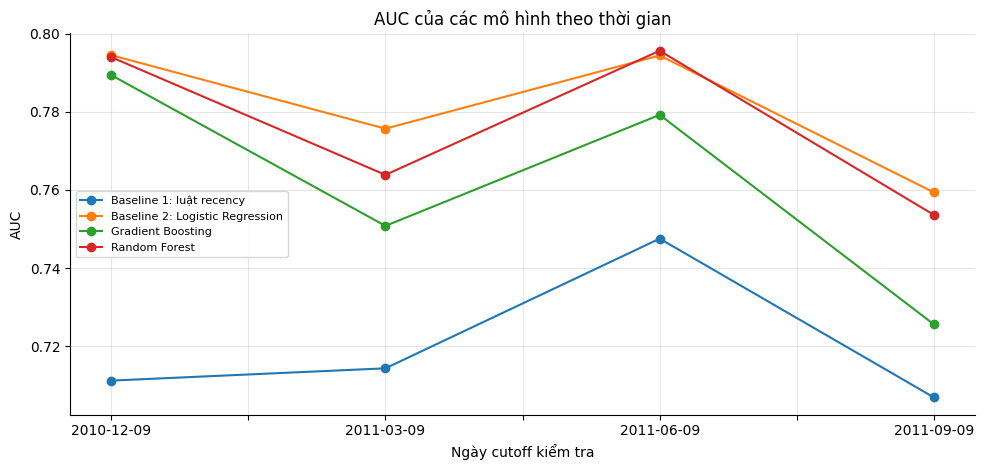

In [7]:
auc_theo_ngay = ket_qua.pivot(index="cutoff", columns="mo_hinh", values="AUC")
ax = auc_theo_ngay.plot(marker="o", figsize=(10, 4.8))
ax.set_ylabel("AUC"); ax.set_xlabel("Ngày cutoff kiểm tra"); ax.set_title("AUC của các mô hình theo thời gian")
ax.legend(fontsize=8); plt.xticks(rotation=0)
plt.tight_layout(); plt.savefig("figures/05_auc_theo_thoi_gian.png", dpi=150); plt.show()

**Nhận xét:**
- Mô hình phức tạp **không phải lúc nào cũng thắng**. Nếu Logistic Regression (baseline 2) ngang hoặc hơn Random Forest/Boosting thì điều đó có nghĩa là phần lớn thông tin đã nằm trong các đặc trưng được tạo ra (recency, nhịp mua, xu hướng), chứ không cần thuật toán phức tạp.
- Mô hình học máy cần **hơn baseline 1 (luật recency)** thì mới có giá trị: đây là bằng chứng việc xây dựng đặc trưng có ích.
- AUC dao động giữa các ngày cutoff có thể do **mùa vụ** (xem tỷ lệ rời bỏ khác nhau ở notebook 04), không hẳn do mô hình "hỏng". Dữ liệu chỉ gần 2 năm nên khó tách hai nguyên nhân này. Nếu một mô hình tụt AUC nhiều hơn các mô hình khác, đó là dấu hiệu nên huấn luyện lại định kỳ.
- **Precision@500** và **Lift@500** cho biết danh sách 500 khách trúng nhiều hơn bao nhiêu so với chọn ngẫu nhiên. Lưu ý khi tỷ lệ rời bỏ chung đã cao (ví dụ 69%) thì Precision@500 cao một phần là do tỷ lệ nền cao, hãy nhìn cả cột Lift.

## 5. Đặc trưng nào quan trọng nhất?

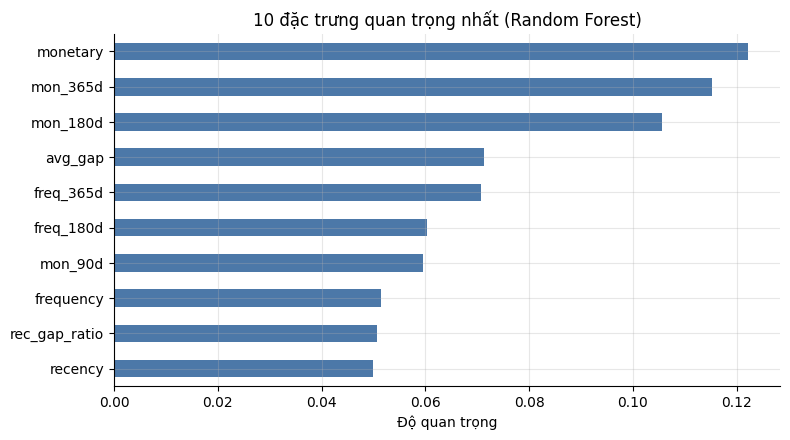

In [8]:
quan_trong = pd.Series(rung.feature_importances_, index=dac_trung).sort_values()
quan_trong.tail(10).plot.barh(color="#4C78A8", figsize=(8, 4.5))
plt.title("10 đặc trưng quan trọng nhất (Random Forest)"); plt.xlabel("Độ quan trọng")
plt.tight_layout(); plt.savefig("figures/05_dac_trung_quan_trong.png", dpi=150); plt.show()

## 6. Lưu kết quả 

In [9]:
ket_qua.to_csv("ket_qua_mo_hinh.csv", index=False, encoding="utf-8-sig")      # mở được bằng Excel
print("Đã lưu ket_qua_mo_hinh.csv:", len(ket_qua), "dòng")

Đã lưu ket_qua_mo_hinh.csv: 16 dòng


## 7. Tổng kết và hạn chế
- Mô hình được đánh giá theo thời gian và so với 2 baseline; chỉ nên chọn mô hình phức tạp nếu AUC và Precision@500 thật sự tốt hơn baseline.
- Hạn chế: dữ liệu ngắn, chưa tinh chỉnh tham số, chỉ dùng nhãn H = 90 ngày.